In [1]:
#NAME(s) =="Audrey, Claire, Jonathan"

## 1. Background Reading (20 points)

Begin by reading **Section 5.3: t-SNE and UMAP for High-Dimensional Data** from the [*Machine Learning Hero* book](https://www.oreilly.com/library/view/machine-learning-hero/9781837025015/), which is available through UVA’s subscription to O’Reilly.

After reading, discuss with your group and respond to the following questions:

a. **Why might we choose t-SNE or UMAP over PCA for dimensionality reduction?**  
Briefly explain the limitations of PCA, and why non-linear methods like t-SNE and UMAP can be more effective in some contexts.

We would choose t-SNE or UMAP over PCA because PCA does not always perform as well on high dimensionality reduction when the patterns in the data are non-linear. PCA can sometimes fall short in capturing non-linear relationships. On the other hand t-SNE and UMAP are good at preserving relationships and patterns within high dimensional data.

The main limitation of PCA is that it is a linear method. It can only rotate the data and project it onto the directions with the most variance (the principal components), so if the data lies on a curved, non-linear shape, PCA cannot unfold it, and points that are far apart along that shape can end up on top of each other. PCA also keeps the directions with the most total variance, and those are not always the directions that separate groups, so smaller differences (like subgroups inside a big cluster) can get mixed together when we only keep 2 components. t-SNE and UMAP instead look at which points are neighbors in the original high dimensional space and try to keep those neighbors close together in 2D, which is why they can show clusters that PCA mixes together. PCA is still useful because it is fast, it gives the same result every time, and its axes and distances are easier to interpret.

b. **Summarize the strengths and weaknesses of t-SNE and UMAP.**  
What are the key differences between the two methods? In what situations might you prefer one over the other?
One strength of t-SNE is that it maintains the relationship between nearby points, which is a great feature for visualizations. A drawback of t-SNE is that when running on large datasets, it can take hours or days. Due to t-SNE's focus on preserving local relationships, it can distort global relationships. This means the size of a cluster and the distance between two clusters in a t-SNE plot do not really mean anything. t-SNE is also random, so the result can change with the random seed and the perplexity, and the standard version cannot place new points into a map it already made.

In turn, UMAP has strengths in many areas such as scalability, faster processing, memory efficiency, parallelization, and preservation of both local and global structure. These computational advantages make UMAP a powerful tool for dimensionality reduction. One weakness for UMAP comes from its need to carefully tune certain parameters in order to reach higher performance outputs. Like t-SNE, UMAP is also random, and the distances between its clusters and the cluster sizes still cannot be read literally. A small min_dist can also make clusters look tighter and more separated than they really are.

When comparing UMAP to t-SNE, UMAP is faster and more scalable. Also, UMAP tends to preserve local and global structure while t-SNE primarily focuses on the local relationships. However, Kobak and Linderman (2021) showed that a lot of this global structure advantage comes from how UMAP is initialized, and t-SNE keeps the global structure about as well when it starts from the same kind of initialization (like PCA). We would prefer UMAP for large datasets, when we need to add new points later (UMAP has a transform method), or when we care about how the clusters are arranged relative to each other. We would prefer t-SNE for smaller datasets where we mainly want to look at the detailed local cluster structure and runtime is not a problem.


c. **What are the main hyperparameters of each method, and what role do they play?**  
Describe how these hyperparameters affect the behavior and output of the algorithms.

For t-SNE, the main hyperparameter is perplexity, which balances the local and global aspects of the data. For UMAP, the main hyperparameters are n_neighbors, which sets the size of the local neighborhood, and min_dist, which controls the minimum distance between points in the low dimensional embedding.

Perplexity is roughly the number of nearest neighbors each point pays attention to (usually between 5 and 50). A low perplexity focuses on very local structure and can break the data into many small, fragmented clusters, while a high perplexity looks at bigger neighborhoods and gives a smoother, more global picture. t-SNE also has other hyperparameters like learning_rate (the step size of the optimization), max_iter (how many optimization steps it runs), early_exaggeration (how much empty space ends up between clusters) and init (whether the starting positions are random or come from PCA). For UMAP, a small n_neighbors (like 5) focuses on fine local detail and can split the data into many small pieces, while a large n_neighbors (like 50) keeps more of the global structure but loses detail. A small min_dist (close to 0) packs the points into tight clumps, while a large min_dist (close to 1) spreads the points out more evenly. UMAP also has n_components (the number of output dimensions) and metric (the distance used in the original space), and for both methods random_state fixes the seed so the results can be reproduced.

**Reference:** Kobak, D. and Linderman, G. C. (2021). Initialization is critical for preserving global data structure in both t-SNE and UMAP. *Nature Biotechnology*, 39, 156-157.

## 2. Experiment with the Palmer Penguins Dataset (Toy Example) (50 points)

To get hands-on experience, you will begin by applying dimensionality reduction techniques to a small and interpretable dataset: Palmer Penguins.

Before you begin coding, read the official documentation for the following methods:

- [PCA](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html) — from `sklearn.decomposition`
- [t-SNE](https://scikit-learn.org/stable/modules/generated/sklearn.manifold.TSNE.html) — from `sklearn.manifold`
- [UMAP](https://umap-learn.readthedocs.io/en/latest/basic_usage.html) — from the `umap-learn` package

After reviewing the documentation, complete the following tasks:

a. Load the Palmer Penguins dataset as demonstrated in the [UMAP documentation](https://umap-learn.readthedocs.io/en/latest/basic_usage.html#penguin-data).  

Select the following numerical features:

- `bill_length_mm`  
- `bill_depth_mm`  
- `flipper_length_mm`  
- `body_mass_g`

Then, **standardize** these features so that each has zero mean and unit variance.

In [2]:
!pip install umap-learn

In [3]:
import numpy as np
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import umap
from sklearn.manifold import TSNE
%matplotlib inline
from sklearn.decomposition import PCA


In [4]:
sns.set(style='white', context='notebook', rc={'figure.figsize':(14,10)})

In [5]:
penguins = pd.read_csv("https://raw.githubusercontent.com/allisonhorst/palmerpenguins/c19a904462482430170bfe2c718775ddb7dbb885/inst/extdata/penguins.csv")
penguins.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


b. Apply **PCA**, **t-SNE**, and **UMAP** to reduce the selected features to **2 dimensions**.

Then, for each method:
- Create a **scatter plot** of the 2D projection.
- Use a different color to represent each **species** in the dataset.

This will help you visually assess how well each method separates the species in the reduced space.

*N.B.* You may need to first install `UMAP-learn`. Follow the [documentation](https://umap-learn.readthedocs.io/en/latest/index.html) for that.

In [6]:
reducer = umap.UMAP()

In [7]:
penguins = penguins.dropna()
penguins.species.value_counts()

species
Adelie       146
Gentoo       119
Chinstrap     68
Name: count, dtype: int64

In [8]:
penguin_data = penguins[
    [
        "bill_length_mm",
        "bill_depth_mm",
        "flipper_length_mm",
        "body_mass_g",
    ]
].values
scaled_penguin_data = StandardScaler().fit_transform(penguin_data)

In [9]:
embedding_1 = reducer.fit_transform(scaled_penguin_data)
embedding_1.shape

(333, 2)

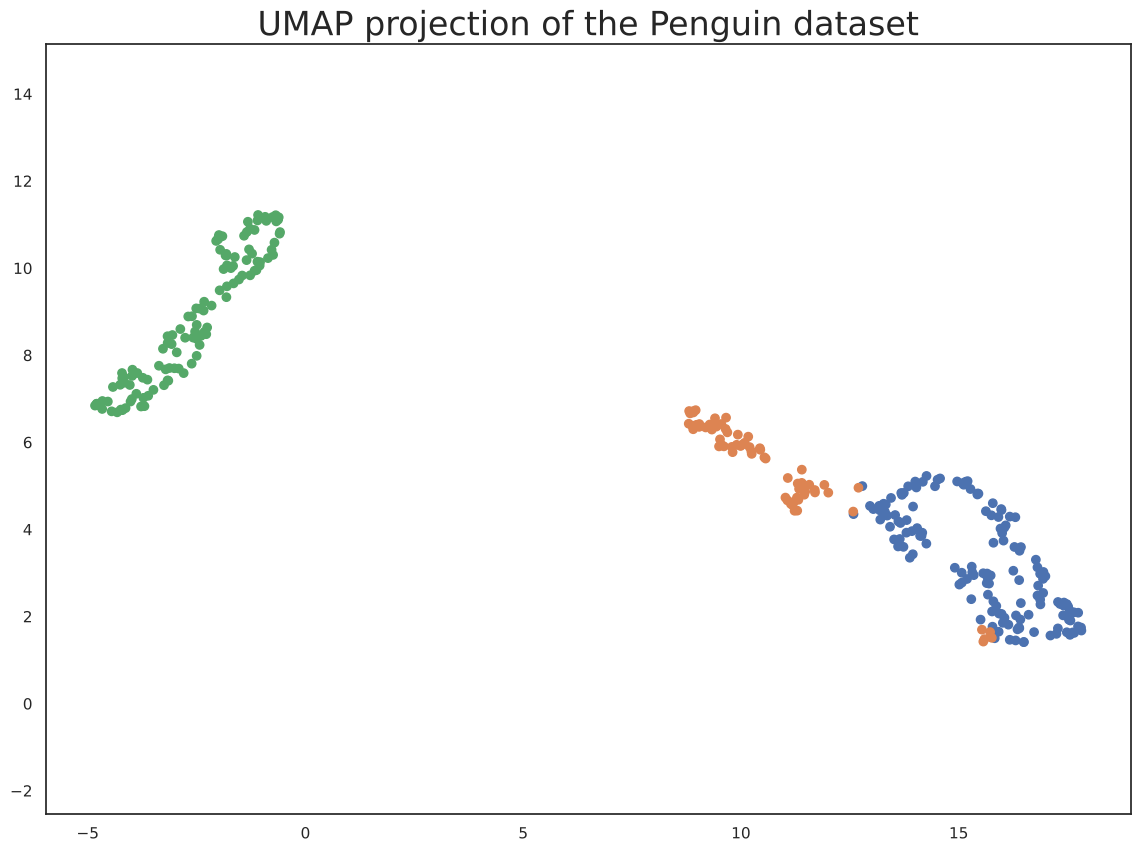

In [10]:
plt.scatter(
    embedding_1[:, 0],
    embedding_1[:, 1],
    c=[sns.color_palette()[x] for x in penguins.species.map({"Adelie":0, "Chinstrap":1, "Gentoo":2})])
plt.gca().set_aspect('equal', 'datalim')
plt.title('UMAP projection of the Penguin dataset', fontsize=24);

In [11]:
embedding = reducer.fit_transform(scaled_penguin_data)
embedding.shape 

X_embedded = TSNE(n_components=2, learning_rate='auto',
                  init='random', perplexity=3).fit_transform(scaled_penguin_data)
X_embedded.shape

(333, 2)

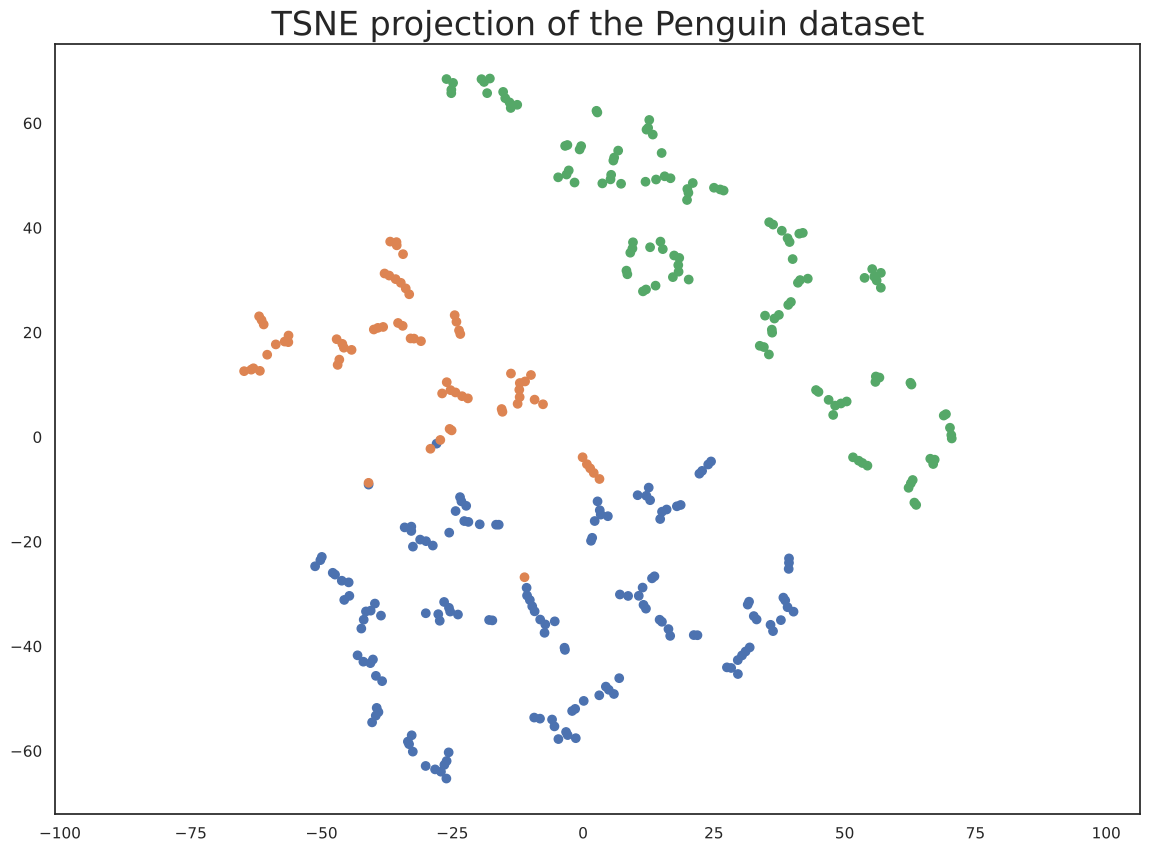

In [12]:
plt.scatter(
    X_embedded[:, 0],
    X_embedded[:, 1],
    c=[sns.color_palette()[x] for x in penguins.species.map({"Adelie":0, "Chinstrap":1, "Gentoo":2})])
plt.gca().set_aspect('equal', 'datalim')
plt.title('TSNE projection of the Penguin dataset', fontsize=24);

In [13]:
embedding = reducer.fit_transform(scaled_penguin_data)
embedding.shape 

pca = PCA(n_components=2, svd_solver='full')
X_pca = pca.fit_transform(scaled_penguin_data)

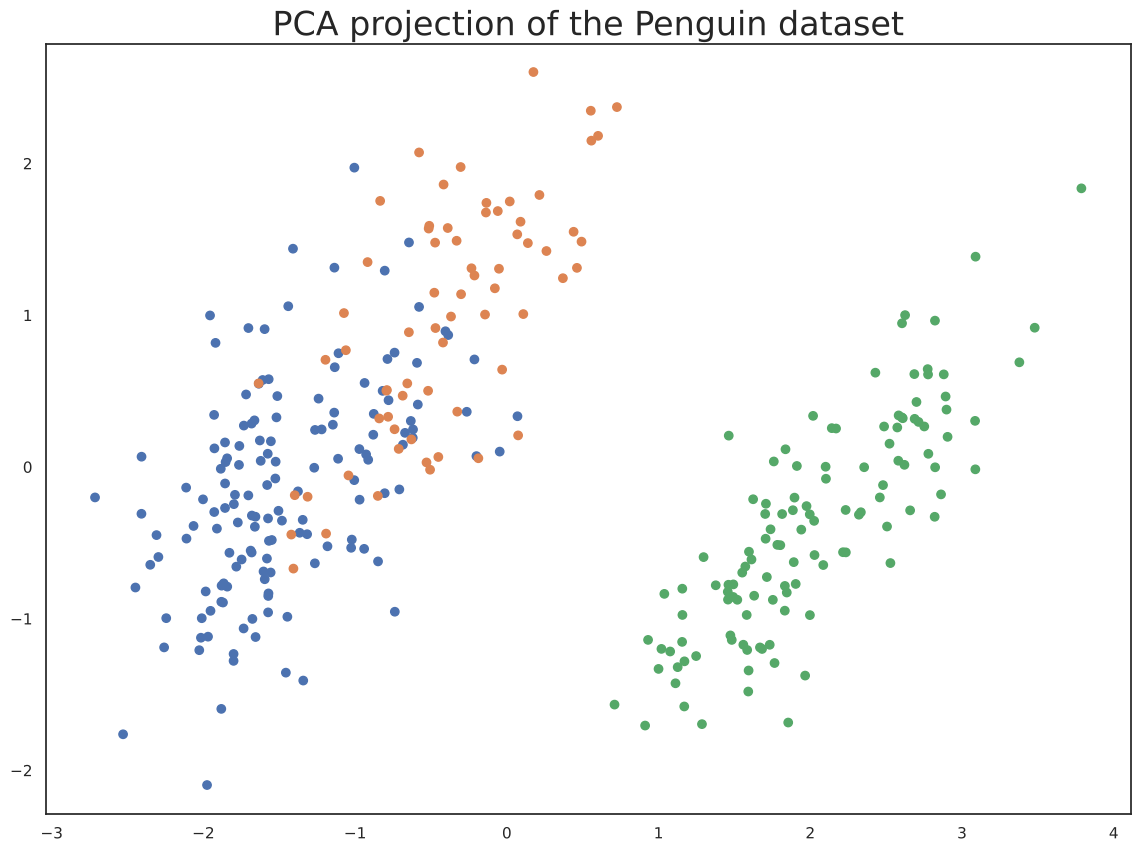

In [14]:
plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=[sns.color_palette()[x] for x in penguins.species.map({"Adelie":0, "Chinstrap":1, "Gentoo":2})])
plt.gca().set_aspect('equal', 'datalim')
plt.title('PCA projection of the Penguin dataset', fontsize=24);

c. Analyze the resulting plots and describe the main patterns you observe.

- Which method produces the most visually separable clusters?
- Are there any species that overlap in one method but not in others?
- What might explain these differences in how the data is projected?

Elaborate on your observations and compare the strengths and limitations of each method based on this toy example.


In [15]:
# Numbers to back up our 2c answer
from sklearn.metrics import silhouette_score

species = penguins.species.values
print("Silhouette score by species (higher = more compact and better separated clusters):")
print("PCA:  ", round(silhouette_score(X_pca, species), 3))
print("t-SNE:", round(silhouette_score(X_embedded, species), 3))
print("UMAP: ", round(silhouette_score(embedding_1, species), 3))

features = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
print("\nAverage measurements for each species:")
print(penguins.groupby("species")[features].mean().round(1))

print("\nPCA loadings (how much each feature counts toward PC1 and PC2):")
print(pd.DataFrame(pca.components_.T, index=features, columns=["PC1", "PC2"]).round(2))
print("Explained variance ratio:", pca.explained_variance_ratio_.round(3))

Silhouette score by species (higher = more compact and better separated clusters):
PCA:   0.427
t-SNE: 0.376
UMAP:  0.654

Average measurements for each species:
           bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
species                                                                 
Adelie               38.8           18.3              190.1       3706.2
Chinstrap            48.8           18.4              195.8       3733.1
Gentoo               47.6           15.0              217.2       5092.4

PCA loadings (how much each feature counts toward PC1 and PC2):
                    PC1   PC2
bill_length_mm     0.45  0.60
bill_depth_mm     -0.40  0.80
flipper_length_mm  0.58  0.01
body_mass_g        0.55  0.08
Explained variance ratio: [0.686 0.195]


- UMAP produced the most visually separated clusters. In the UMAP plot each species formed a tight and compact group and there is a lot of empty space around Gentoo. Also, the t-SNE plot shows three groups (one area for each species), but its clusters are looser and more spread out, and because we used a very low perplexity (3), each species is broken up into many small pieces. UMAP has the highest silhouette score, which measures how compact and far apart the clusters are, while t-SNE scores much lower because of all those small pieces (see the scores in the cell above).
- I would say Gentoo is completely separated in all three methods, while Adelie and Chinstrap overlap a lot in the PCA plot but are mostly separated in t-SNE and UMAP (only a few Chinstraps end up next to the Adelie group).
- The species averages and the PCA loadings explain most of it. Gentoo penguins are much bigger than the other two (about 5,090 g vs about 3,700 to 3,730 g, with flippers around 217 mm vs 190 to 196 mm) and have shallower bills, so they differ from the other two species in bill depth, flipper length and body mass, and only their bill length is close to Chinstrap's (47.6 vs 48.8 mm). This size difference is the biggest source of variance in the data, so it is what PC1 picks up (PC1 has positive loadings on flipper length, body mass and bill length and a negative loading on bill depth), which is why PCA separates Gentoo so well. Adelie and Chinstrap have almost the same body mass, flipper length and bill depth and mainly differ in bill length (38.8 vs 48.8 mm), and PCA's first two components only partly capture that difference, so they overlap in the PCA plot. t-SNE and UMAP do not look for directions of high variance. They use all four features to find each penguin's nearest neighbors and try to keep those neighbors together in 2D, so they can pull Adelie and Chinstrap apart.
- Strengths and limitations: PCA is fast, gives the same result every time, and its axes and distances are easier to interpret (for example, Gentoo really is far from the other two species), but its linear 2D projection mixes Adelie and Chinstrap. t-SNE and UMAP separate all three species better, but their axes have no meaning, the distances between clusters and the cluster sizes are not meaningful, and the results depend on the hyperparameters (like the low perplexity we used for t-SNE) and the random seed, so these plots change a bit every time we run them.

d. For **t-SNE** and **UMAP**, explore how different hyperparameter settings affect the resulting 2D projections.

- For **t-SNE**, vary the `perplexity` parameter (e.g., 5, 30, 50).
- For **UMAP**, vary the `n_neighbors` parameter (e.g., 5, 15, 50) and optionally `min_dist`.
- Keep `random_state` fixed across all runs so that differences between projections are due primarily to changes in the hyperparameters rather than random initialization.

For each configuration:
- Plot the resulting 2D projection.
- Use color to represent species.

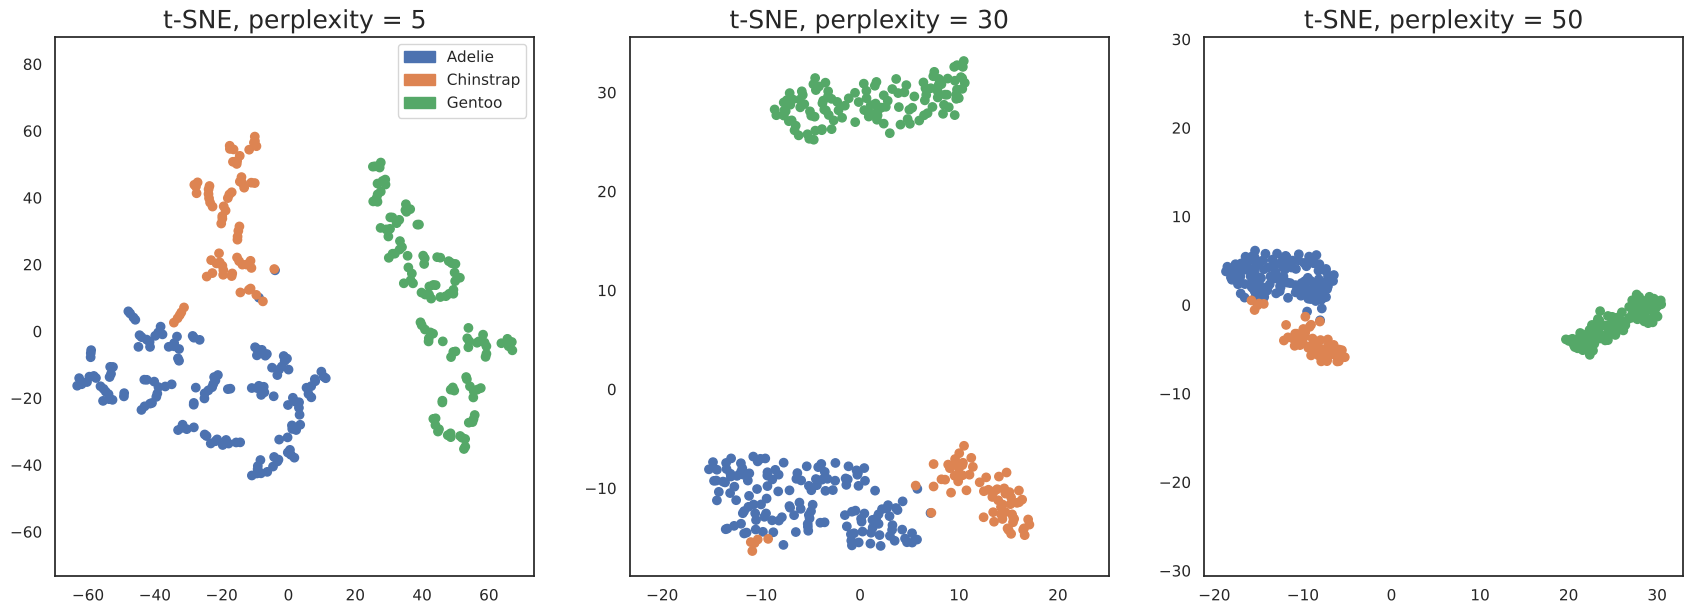

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


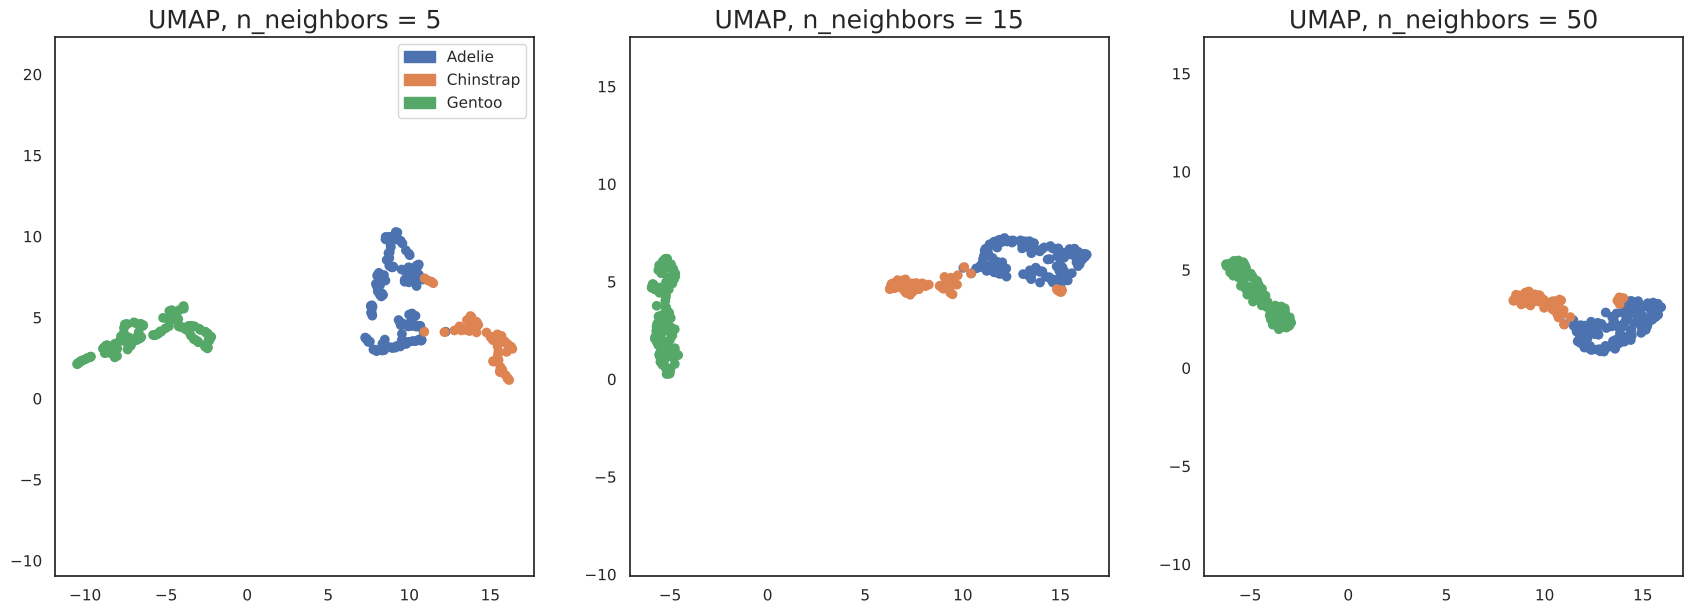

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


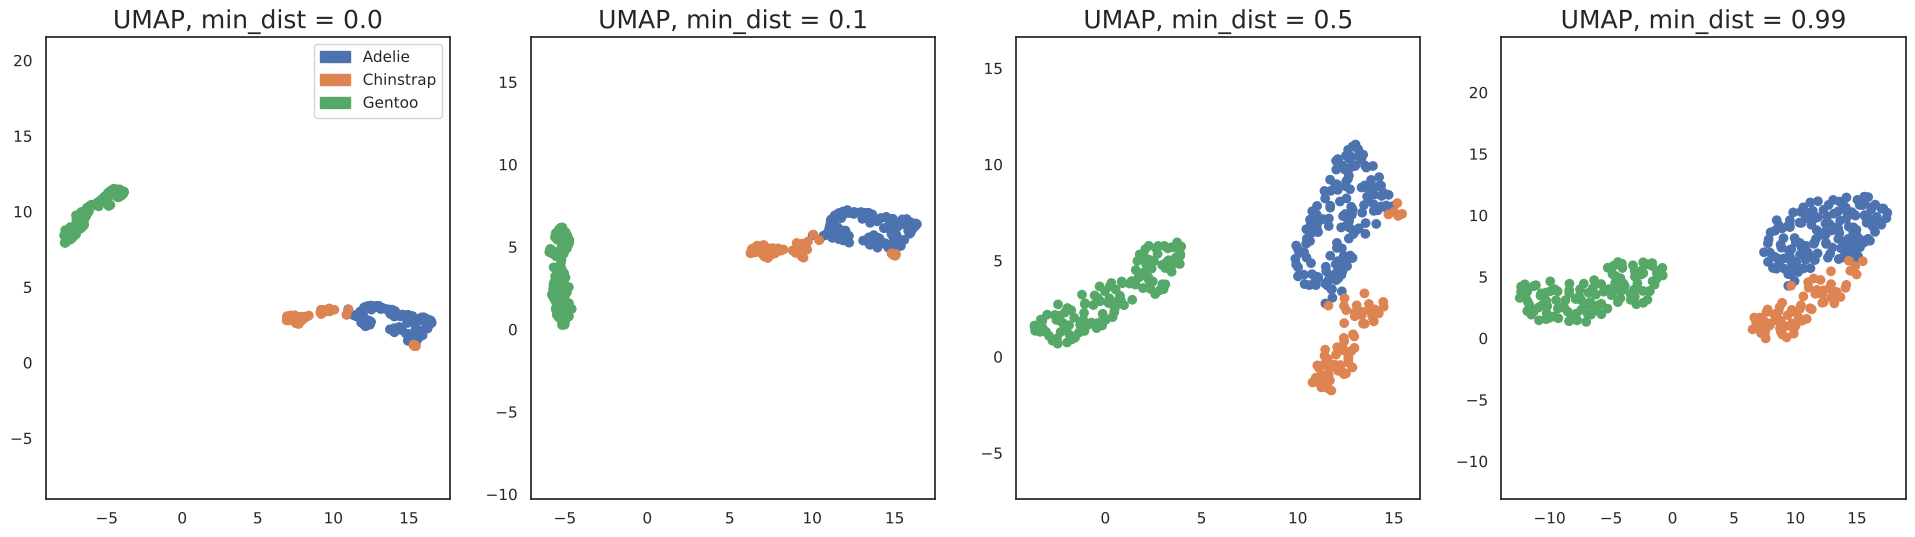

In [16]:
# YOUR CODE HERE
from matplotlib.patches import Patch
RANDOM_STATE = 42

# same species coloring we used in 2b, plus a legend
species_colors = [sns.color_palette()[x] for x in penguins.species.map({"Adelie": 0, "Chinstrap": 1, "Gentoo": 2})]
legend_handles = [Patch(color=sns.color_palette()[i], label=name)
                  for i, name in enumerate(["Adelie", "Chinstrap", "Gentoo"])]

# t-SNE: vary perplexity
perplexities = [5, 30, 50]
fig, axes = plt.subplots(1, 3, figsize=(21, 7))
for ax, p in zip(axes, perplexities):
    X_tsne = TSNE(n_components=2, learning_rate='auto', init='random',
                  perplexity=p, random_state=RANDOM_STATE).fit_transform(scaled_penguin_data)
    ax.scatter(X_tsne[:, 0], X_tsne[:, 1], c=species_colors)
    ax.set_aspect('equal', 'datalim')
    ax.set_title(f't-SNE, perplexity = {p}', fontsize=18)
axes[0].legend(handles=legend_handles)
plt.show()

# UMAP: vary n_neighbors (min_dist stays at the default 0.1)
n_neighbors_list = [5, 15, 50]
fig, axes = plt.subplots(1, 3, figsize=(21, 7))
for ax, n in zip(axes, n_neighbors_list):
    X_umap = umap.UMAP(n_neighbors=n, min_dist=0.1,
                       random_state=RANDOM_STATE).fit_transform(scaled_penguin_data)
    ax.scatter(X_umap[:, 0], X_umap[:, 1], c=species_colors)
    ax.set_aspect('equal', 'datalim')
    ax.set_title(f'UMAP, n_neighbors = {n}', fontsize=18)
axes[0].legend(handles=legend_handles)
plt.show()

# UMAP: vary min_dist (n_neighbors stays at the default 15)
min_dists = [0.0, 0.1, 0.5, 0.99]
fig, axes = plt.subplots(1, 4, figsize=(24, 6))
for ax, d in zip(axes, min_dists):
    X_umap = umap.UMAP(n_neighbors=15, min_dist=d,
                       random_state=RANDOM_STATE).fit_transform(scaled_penguin_data)
    ax.scatter(X_umap[:, 0], X_umap[:, 1], c=species_colors)
    ax.set_aspect('equal', 'datalim')
    ax.set_title(f'UMAP, min_dist = {d}', fontsize=18)
axes[0].legend(handles=legend_handles)
plt.show()

After generating the plots, describe the main changes you observe in the visualizations:
- How do the clusters shift, stretch, or separate as hyperparameters change?
- Which settings appear to better preserve the structure of the data?

Elaborate on your observations and support your discussion with specific visual examples.

As we increased perplexity for t-SNE and n_neighbors for UMAP, the clusters went from being broken up into lots of small pieces to forming smoother and more compact groups. With perplexity 5 and n_neighbors 5, each species was split into small chains and curls (Gentoo even looked like a long snake in UMAP), which makes it look like there are subgroups that are not really there. With perplexity 30 to 50 and n_neighbors 15 to 50, Gentoo formed its own cluster far away from the other two, while Adelie and Chinstrap stayed right next to each other with only a few Chinstraps mixed into the Adelie group. Changing min_dist mostly changed how tightly the points were packed, since min_dist = 0 squeezed each species into a thin line and min_dist = 0.99 spread them out into big, even clouds with smaller gaps between them. Overall, perplexity 30 to 50 and n_neighbors 15 to 50 with the default min_dist of 0.1 preserved the structure of the data best, because they show Gentoo as clearly different and Adelie and Chinstrap as similar, which matches what we saw in the PCA plot.

## 3. Apply to Real Data (1000 Genomes Subset) (25 points)

Your goal in this section is to try to create a figure similar to Figure 1 of the Diaz-Papkovich *et al.* (2019) paper, using a subset of genotype data from the 1000 Genomes Project.

To do so, complete the following steps:

a. Load the genotype dataset accompanying this lab, where each row corresponds to an individual, and each column to a genetic variant. Load also the provided population labels for each individual. 

b. **Standardize** the features (i.e., transform the genotype values to have zero mean and unit variance).

c. Apply **PCA**, **t-SNE**, and **UMAP** to reduce the data to 2 dimensions. You may use the default values for the rest of hyperparameters in these techniques. 

d. Create **scatter plots** of the resulting projections, coloring each point according to its **population group**.

e. Reflect on the following questions:
- Explain what you observe in each case. Additionally, which method appears to provide the best visual separation of the population into distinct groups? Elaborate on why this might be the case, based on what you know about each method.
- What changes if you first reduce the data to the **top 25 PCA components**, and then apply t-SNE or UMAP?
- In your opinion, what are the trade-offs between **interpretability** (e.g., preservation of local and global structure) and **performance** (e.g., visual separation of known populations and computational time) when using these dimensionality reduction methods?

Please elaborate on your answers and use the plots to support your discussion.

In [17]:
#Load data
data = np.load("genome_data_lab3.npy")
genome = pd.DataFrame(data)
labels = pd.read_csv("population_labels_lab3.txt", header=None)
print(genome.head())
print(labels.head())

   0    1    2    3    4    5    6    7    8    9    ...  858  859  860  861  \
0    0    1    1    2    1    1    2    1    0    0  ...    0    0    0    0   
1    0    1    2    1    0    1    1    2    0    0  ...    0    0    0    0   
2    0    2    1    0    1    0    2    2    1    0  ...    0    0    0    0   
3    2    2    1    1    0    2    2    2    1    0  ...    0    0    1    0   
4    1    2    1    0    0    0    0    2    0    0  ...    0    0    0    0   

   862  863  864  865  866  867  
0    2    0    0    2    0    1  
1    2    0    0    1    0    1  
2    2    0    2    0    0    1  
3    1    0    0    0    0    1  
4    2    0    1    0    0    2  

[5 rows x 868 columns]
     0
0  GBR
1  GBR
2  GBR
3  GBR
4  GBR


In [18]:
#Standardize data
genome_standardized = StandardScaler().fit_transform(genome)

In [19]:
#PCA
embedding_pca_genome = PCA(n_components=2, random_state=42).fit_transform(genome_standardized)

#TSNE
embedding_tsne_genome = TSNE(n_components=2, random_state=42).fit_transform(genome_standardized)

#UMAP
embedding_umap_genome = umap.UMAP(n_components=2, random_state=42).fit_transform(genome_standardized)

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


In [20]:
# Load and standardize the genotype data
genome = np.load("genome_data_lab3.npy").astype(float)
X_genome_scaled = StandardScaler().fit_transform(genome)

# 2D projections used by the plotting cell
pca_genome = PCA(n_components=2, random_state=42).fit_transform(X_genome_scaled)
embedding_tsne_genome = TSNE(n_components=2, random_state=42).fit_transform(X_genome_scaled)
embedding_umap_genome = umap.UMAP(random_state=42).fit_transform(X_genome_scaled)

# For 3e: reduce to the top 25 PCs first, then run t-SNE / UMAP
X_pca25 = PCA(n_components=25, random_state=42).fit_transform(X_genome_scaled)
embedding_tsne_pca25 = TSNE(n_components=2, random_state=42).fit_transform(X_pca25)
embedding_umap_pca25 = umap.UMAP(random_state=42).fit_transform(X_pca25)

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Unmapped codes: <StringArray>
[]
Length: 0, dtype: str


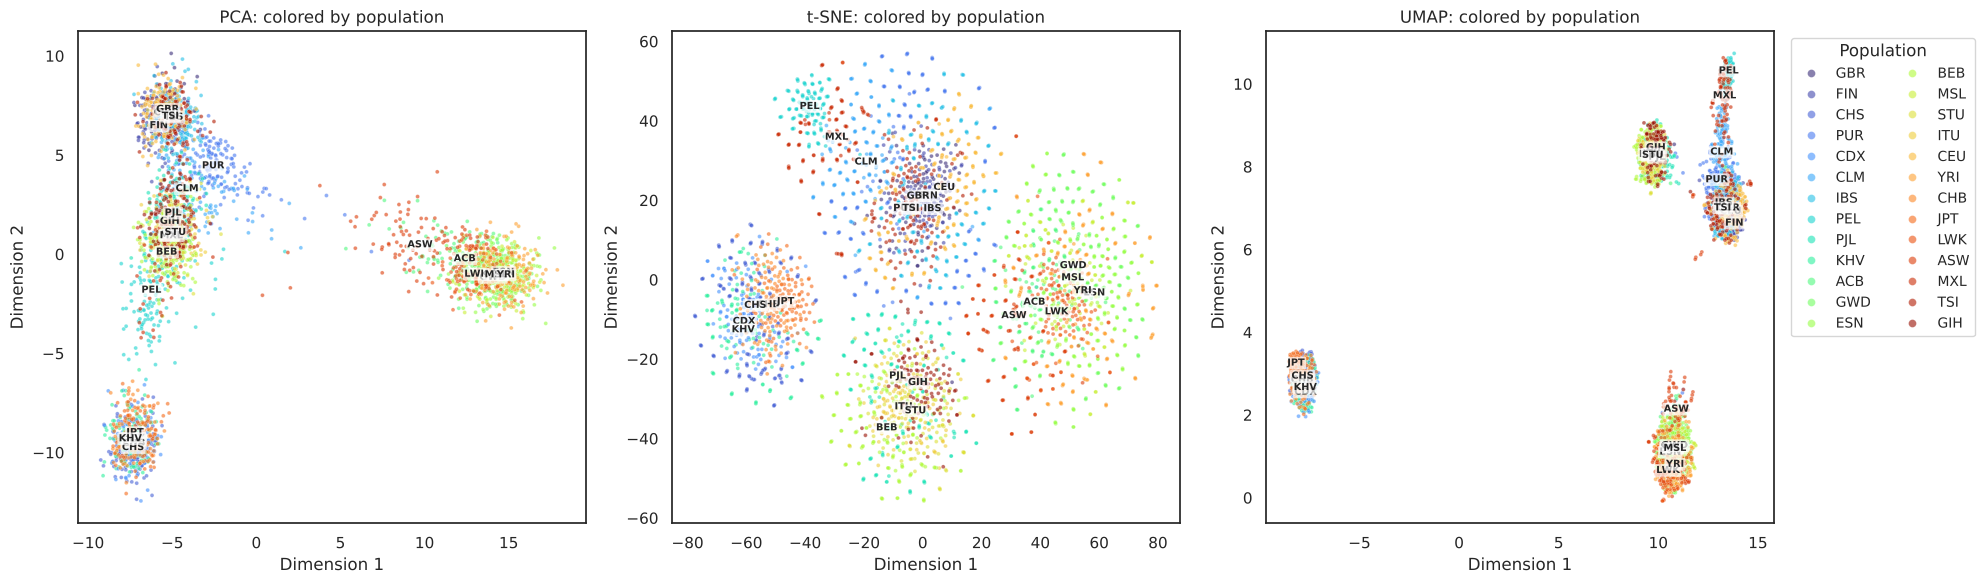

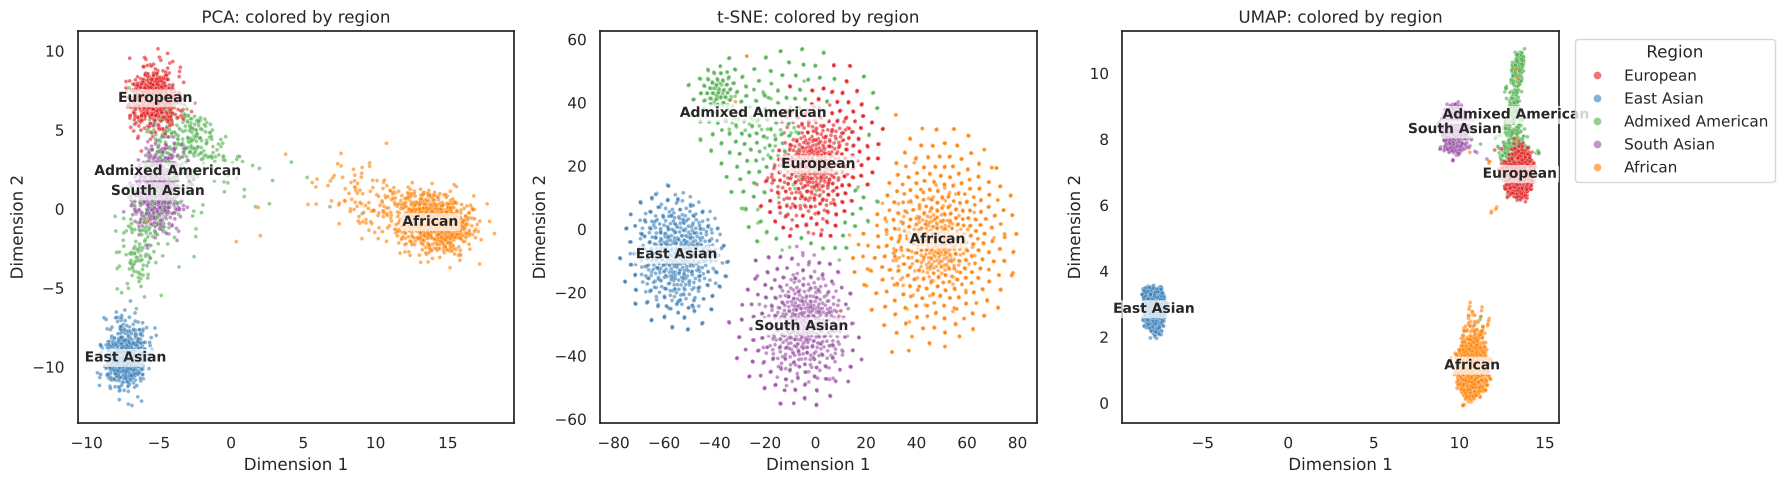

In [21]:
#Scatter plots

#Info is from this ReadMe https://ftp.1000genomes.ebi.ac.uk/vol1/ftp/README_populations.md from the 1000 genomes project site
info = {
    #East Asian
    "CHB": ("Han Chinese in Beijing, China", "East Asian"),
    "JPT": ("Japanese in Tokyo, Japan", "East Asian"),
    "CHS": ("Han Chinese South", "East Asian"),
    "CDX": ("Chinese Dai in Xishuangbanna, China", "East Asian"),
    "KHV": ("Kinh in Ho Chi Minh City, Vietnam", "East Asian"),

    #European
    "CEU": ("Utah residents with Northern and Western European ancestry", "European"),
    "TSI": ("Toscani in Italia", "European"),
    "GBR": ("British in England and Scotland", "European"),
    "FIN": ("Finnish in Finland", "European"),
    "IBS": ("Iberian populations in Spain", "European"),

    #African
    "YRI": ("Yoruba in Ibadan, Nigeria", "African"),
    "LWK": ("Luhya in Webuye, Kenya", "African"),
    "GWD": ("Gambian in Western Division, The Gambia", "African"),
    "MSL": ("Mende in Sierra Leone", "African"),
    "ESN": ("Esan in Nigeria", "African"),
    "ASW": ("African ancestry in Southwest USA", "African"),
    "ACB": ("African Caribbean in Barbados", "African"),

    #Admixed American
    "MXL": ("Mexican ancestry in Los Angeles, California", "Admixed American"),
    "PUR": ("Puerto Rican in Puerto Rico", "Admixed American"),
    "CLM": ("Colombian in Medellin, Colombia", "Admixed American"),
    "PEL": ("Peruvian in Lima, Peru", "Admixed American"),

    #South Asian
    "GIH": ("Gujarati Indian in Houston, Texas", "South Asian"),
    "PJL": ("Punjabi in Lahore, Pakistan", "South Asian"),
    "BEB": ("Bengali in Bangladesh", "South Asian"),
    "STU": ("Sri Lankan Tamil in the UK", "South Asian"),
    "ITU": ("Indian Telugu in the UK", "South Asian"),
}


pop = labels[0]
group = pop.map({code: region for code, (desc, region) in info.items()})
print("Unmapped codes:", pop[group.isna()].unique())

projections = [
    (pca_genome, "PCA"), 
    (embedding_tsne_genome, "t-SNE"), 
    (embedding_umap_genome, "UMAP")
]

def add_labels(ax, emb, names, fontsize=8):
    names = np.asarray(names)
    for n in np.unique(names):
        m = names == n
        ax.text(np.median(emb[m, 0]), np.median(emb[m, 1]), n,
                fontsize=fontsize, weight="bold", ha="center", va="center",
                bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.7))


#All samples, colored and labeled by population
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for i, (ax, (emb, method)) in enumerate(zip(axes, projections)):
    sns.scatterplot(x=emb[:, 0], y=emb[:, 1], hue=pop.values, palette="turbo",
                    s=8, alpha=0.6, legend=(i == 2), ax=ax)
    add_labels(ax, emb, pop.values, fontsize=7)
    ax.set_title(f"{method}: colored by population")
    ax.set_xlabel("Dimension 1")
    ax.set_ylabel("Dimension 2")
axes[2].legend(title="Population", bbox_to_anchor=(1.02, 1), loc="upper left",
               ncol=2, fontsize="small", markerscale=2)
plt.tight_layout()
plt.show()

#All samples, colored and labeled by region
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i, (ax, (emb, method)) in enumerate(zip(axes, projections)):
    sns.scatterplot(x=emb[:, 0], y=emb[:, 1], hue=group.values, palette="Set1",
                    s=8, alpha=0.6, legend=(i == 2), ax=ax)
    add_labels(ax, emb, group.values, fontsize=10)
    ax.set_title(f"{method}: colored by region")
    ax.set_xlabel("Dimension 1")
    ax.set_ylabel("Dimension 2")
axes[2].legend(title="Region", bbox_to_anchor=(1.02, 1), loc="upper left", markerscale=2)
plt.tight_layout()
plt.show()

Observations:

PCA:

East Asian (bottom left), European (top left), South Asian (middle left), Admixed American (also middle left, between the European and South Asian groups, with a few PUR samples stretching a little to the right), African (middle right)
The groups are connected by continuous trails, not separated by clear gaps. The ASW and ACB samples form a gradient from the African cluster across to the European cluster (which makes sense because they have both African and European ancestry, and the 1000 Genomes Project groups them with the African populations), and a second trail (mostly PEL, the population with the most Indigenous American ancestry) runs down from the Admixed American group toward the East Asian cluster.
European, South Asian, and Admixed American are very close and partly overlap.

TSNE:

East Asian (middle left), Admixed American (top left/middle, wrapped around the European cluster), European (top middle), African (middle right), South Asian (bottom middle)
The Admixed American samples are spread out around the European cluster, so they overlap with it, and the ASW and ACB samples sit on the side of the African cluster closest to the European cluster.
Clusters are broad and diffuse. The gaps between the other clusters look clean, but the distances and cluster sizes are not meaningful.

UMAP:

East Asian (bottom left), South Asian (top/middle right), African (bottom right), European (middle right), Admixed American (top right, as a strand coming out of the European cluster where it overlaps with European)
Clusters are compact and distinct. The ASW and ACB samples sit at the top of the African cluster, facing the European cluster, and a few African samples are placed in the gap between the two.

UMAP gives the cleanest visual separation of the continental groups. PCA is linear and shows only the two directions of greatest variance, but it preserves global structure. This is visible in the East Asian, European, and African groups being far apart, in the ASW and ACB samples forming a gradient between the African and European clusters, and in the PEL samples trailing toward the East Asian cluster. However, PCA blurs the South Asian cluster into the European and Admixed American samples. t-SNE preserves local neighborhoods, so genetically similar samples group into distinct clusters. This gives clearer separation than PCA, especially between the South Asian and European groups. However, t-SNE does not preserve global distances well, so its clusters are spread out and the gaps between them are not meaningful. UMAP also preserves local structure and is usually described as retaining more global structure than t-SNE, and it packs clusters more tightly. This produces the most compact, distinct groups with clear gaps between them. The global layout of the UMAP plot is still not fully reliable though. For example, UMAP places the African cluster right below the European cluster and pushes the East Asian cluster far away from every other group, even though PCA shows that the African populations are the most different from everyone else (they are separated along PC1). In the UMAP plot, the Admixed American samples (for example CLM and PUR) sit against the European cluster, and the ASW and ACB samples sit at the edge of the African cluster that faces the Europeans. This is likely not a modeling error but rather a reflection of these populations' mixed ancestry. The Admixed American populations have European, Indigenous American and some African ancestry, while ASW and ACB have mostly African ancestry with some European ancestry.

Share of the total variance kept by the top 25 PCs: 0.19


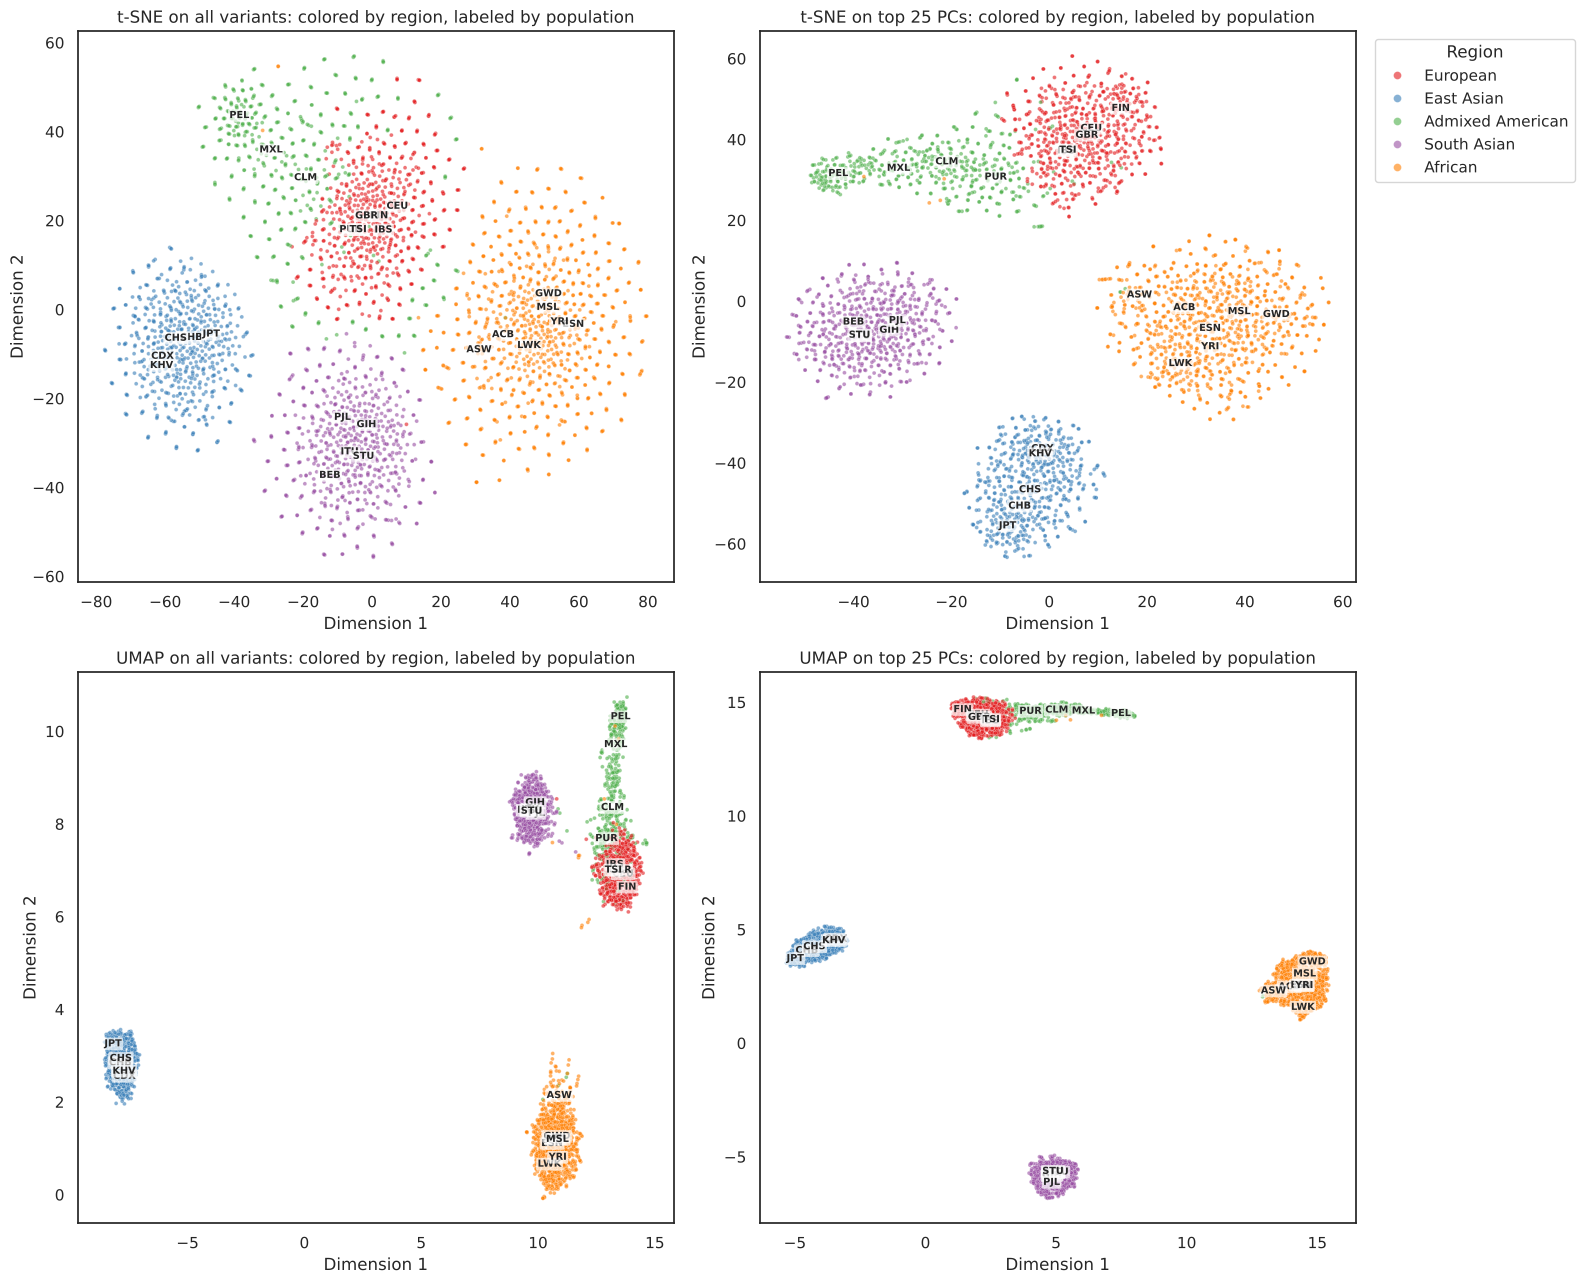

In [22]:
#3e: t-SNE and UMAP on the top 25 PCs vs on all the variants
pca25 = PCA(n_components=25, random_state=42).fit(X_genome_scaled)
print("Share of the total variance kept by the top 25 PCs:", round(pca25.explained_variance_ratio_.sum(), 3))

projections_pca25 = [
    (embedding_tsne_genome, "t-SNE on all variants"),
    (embedding_tsne_pca25, "t-SNE on top 25 PCs"),
    (embedding_umap_genome, "UMAP on all variants"),
    (embedding_umap_pca25, "UMAP on top 25 PCs"),
]

fig, axes = plt.subplots(2, 2, figsize=(16, 13))
for i, (ax, (emb, method)) in enumerate(zip(axes.ravel(), projections_pca25)):
    sns.scatterplot(x=emb[:, 0], y=emb[:, 1], hue=group.values, palette="Set1",
                    s=8, alpha=0.6, legend=(i == 1), ax=ax)
    add_labels(ax, emb, pop.values, fontsize=7)
    ax.set_title(f"{method}: colored by region, labeled by population")
    ax.set_xlabel("Dimension 1")
    ax.set_ylabel("Dimension 2")
axes[0, 1].legend(title="Region", bbox_to_anchor=(1.02, 1), loc="upper left", markerscale=2)
plt.tight_layout()
plt.show()

In [23]:
#Computational time of each method (for the trade-off question in 3e)
import time

runs = [
    ("PCA", lambda: PCA(n_components=2, random_state=42).fit_transform(X_genome_scaled)),
    ("t-SNE", lambda: TSNE(n_components=2, random_state=42).fit_transform(X_genome_scaled)),
    ("UMAP", lambda: umap.UMAP(random_state=42).fit_transform(X_genome_scaled)),
    ("t-SNE on top 25 PCs", lambda: TSNE(n_components=2, random_state=42).fit_transform(X_pca25)),
    ("UMAP on top 25 PCs", lambda: umap.UMAP(random_state=42).fit_transform(X_pca25)),
]
for name, run in runs:
    start = time.time()
    run()
    print(f"{name}: {time.time() - start:.1f} seconds")

PCA: 0.3 seconds


t-SNE: 12.2 seconds


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP: 14.6 seconds


t-SNE on top 25 PCs: 9.9 seconds


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP on top 25 PCs: 13.5 seconds


**What changes if we first reduce the data to the top 25 PCA components, and then apply t-SNE or UMAP?**

The top 25 PCs only keep about 19% of the total variance, but that is where the main population structure is, and most of the remaining variance is spread across hundreds of small components that look more like random noise from individual variants than population structure. When we run t-SNE and UMAP on these 25 PCs instead of all 868 variants (see the 2 by 2 plot above):

- The continental groups become tighter and more separated. In t-SNE the groups now have clear gaps between them (except the Admixed American strand, which is attached to the Europeans) instead of being big diffuse clouds that almost touch, and in UMAP they become four very compact islands, with the Admixed Americans as a tail on the European one.
- The Admixed American samples become their own structure. With t-SNE on all variants they were spread around the European cluster, but on the top 25 PCs they form a strand attached to the European cluster that is ordered from PUR (closest to the Europeans) to CLM, MXL and then PEL at the far end, which follows how much Indigenous American ancestry each population has. UMAP shows the same ordering as a tail coming out of the European cluster.
- More structure shows up inside the continents. For example, in the t-SNE plot the East Asian cluster goes from JPT and CHB at one end to CHS and then CDX and KHV at the other end, which roughly follows geography from north to south, and in the African cluster ASW sits at one edge while LWK (from Kenya) and GWD (from The Gambia) end up on opposite sides.
- It is a bit faster, since t-SNE and UMAP only have to work with 25 numbers per person instead of 868 (see the timing cell).
- The global arrangement gets worse though. The clusters are placed as isolated islands around the plot, and their positions no longer match the PCA picture. For example, in UMAP on the top 25 PCs the South Asian cluster ends up on the opposite side of the plot from the European cluster, and the European and East Asian clusters end up closest to each other, even though in PCA the South Asians sit between the Europeans and the East Asians.

**What are the trade-offs between interpretability and performance?**

PCA is the most interpretable method. It was the fastest by far, it gives the same result every time, its axes mean something (PC1 separates the African populations from everyone else and PC2 separates Europeans from East Asians), and it keeps the global structure, so admixed samples like ASW and ACB land between their source populations. But it gives the weakest visual separation of the populations, and groups that are not closely related (like the Admixed Americans and South Asians) end up on top of each other. t-SNE and UMAP perform much better at separating the known groups and keeping local neighborhoods, but they give up interpretability. Their axes have no meaning, the cluster sizes and the distances between clusters cannot be read literally, and the results depend on the hyperparameters and the random seed. They also take much longer to run (in our timing cell, PCA took a fraction of a second while t-SNE and UMAP each took around ten seconds or more), and t-SNE gets especially slow on very large datasets. Running them on the top 25 PCs gave the cleanest separation of the continental groups and was a little faster, but it made the global layout even less meaningful. In our opinion, the best approach is to use the methods together. We would use PCA first to see the global structure and to remove noise, and then use UMAP (or t-SNE) on the top PCs to look for finer clusters, while only trusting the local structure (who is next to whom) in those plots.

## 4. Collaboration Reflection (5 points)

As a group, identify **one specific challenge or inefficiency** you encountered while working on this lab. In 3–5 sentences:

1. Briefly describe what happened and how it affected your work.
2. Identify one concrete action your group will take to avoid or better manage this issue in the next lab.

If your group encountered no major problem, identify one aspect of your collaboration that could still be improved.

Our main challenge was keeping our work in sync. We split up the sections and each worked in our own copy of the notebook (some in Codespaces and some downloaded locally), then combined them at the end. Because each of us wrote code on our own, the pieces did not always fit together. For example, the Part 3 plotting code referred to a variable called pca_genome, but the cell that computed the PCA had named it embedding_pca_genome, so the notebook threw a NameError and we had to spend time tracking down which copy and which cell was out of date. For the next lab, we will work from a single notebook in our shared GitHub repo, agree on variable names for shared results before splitting up the work, and run “Restart Kernel and Run All” before every push so problems like this show up right away instead of at the end.